# Step 6: Sales & Demand Forecasting

**E-Commerce 360° Business Intelligence Platform**

Chronological holdout validation, baseline benchmarks, and evaluation metrics.


### 1. Chronological Holdout Design
Given time-series macro-trends, we partition the dataset chronologically:
- **Training Window:** September 2016 through April 2018.
- **Testing/Holdout Window:** May 2018 through August 2018.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

PROCESSED_DIR = r'data/processed'
df = pd.read_csv(f'{PROCESSED_DIR}/order_summary_bi.csv')
delivered = df[df['order_status'] == 'delivered'].copy()
delivered['order_date'] = pd.to_datetime(delivered['purchase_date'])
delivered['sales_month'] = delivered['order_date'].dt.to_period('M')

m_sales = delivered.groupby('sales_month')['total_item_revenue'].sum().reset_index()
m_sales.columns = ['sales_month', 'revenue']
m_sales['month_str'] = m_sales['sales_month'].astype(str)

train = m_sales[m_sales['month_str'] < '2018-05'].copy()
test = m_sales[(m_sales['month_str'] >= '2018-05') & (m_sales['month_str'] <= '2018-08')].copy()
print(f'Train samples: {len(train)} months | Test samples: {len(test)} months')

Train samples: 19 months | Test samples: 4 months


### 2. Baseline Models Evaluation
Compare Persistence Baseline ($y_t = y_{t-1}$) against 3-Month Moving Average.

In [2]:
# Persistence Baseline (Lag 1)
test_actual = test['revenue'].values
lag_pred = [train['revenue'].iloc[-1]] + list(test_actual[:-1])

ma3_val = train['revenue'].iloc[-3:].mean()
ma3_pred = [ma3_val] * len(test)

mape_lag = mean_absolute_percentage_error(test_actual, lag_pred) * 100
rmse_lag = np.sqrt(mean_squared_error(test_actual, lag_pred))

mape_ma3 = mean_absolute_percentage_error(test_actual, ma3_pred) * 100
rmse_ma3 = np.sqrt(mean_squared_error(test_actual, ma3_pred))

print(f'Persistence (Lag-1)  -> MAPE: {mape_lag:.2f}%, RMSE: R$ {rmse_lag:,.2f}')
print(f'Moving Average (3M)  -> MAPE: {mape_ma3:.2f}%, RMSE: R$ {rmse_ma3:,.2f}')

Persistence (Lag-1)  -> MAPE: 4.87%, RMSE: R$ 62,797.90
Moving Average (3M)  -> MAPE: 7.13%, RMSE: R$ 63,509.32


### 3. Forecast vs. Actual Visual Comparison

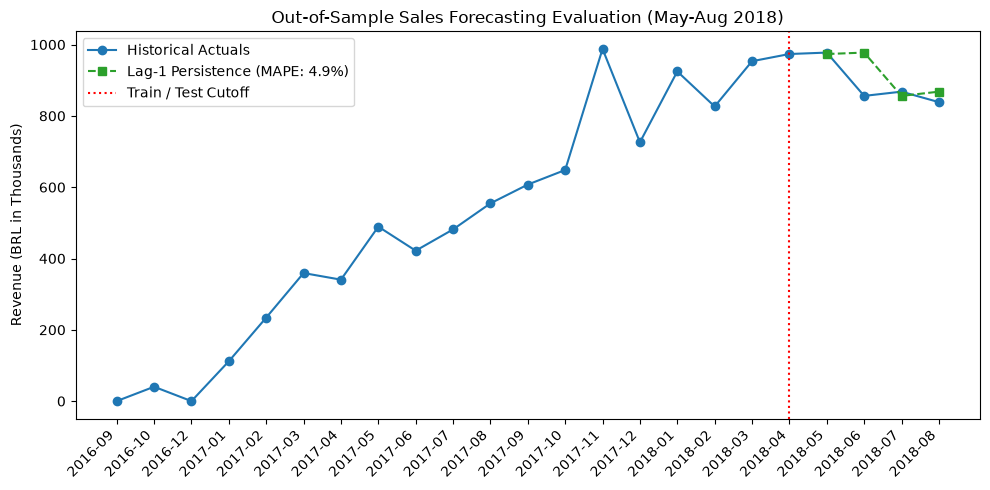

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(m_sales['month_str'], m_sales['revenue'] / 1e3, marker='o', label='Historical Actuals', color='#1f77b4')
plt.plot(test['month_str'], np.array(lag_pred) / 1e3, marker='s', linestyle='--', label=f'Lag-1 Persistence (MAPE: {mape_lag:.1f}%)', color='#2ca02c')
plt.axvline(train['month_str'].iloc[-1], color='red', linestyle=':', label='Train / Test Cutoff')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Revenue (BRL in Thousands)')
plt.title('Out-of-Sample Sales Forecasting Evaluation (May-Aug 2018)')
plt.legend()
plt.tight_layout()
plt.show()